# HW2 : Convergence uniforme et limites de l'apprentissage

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Pour que les résultats soient reproductibles
rng = np.random.default_rng(2026)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
from IPython.display import display, Markdown

def show_table(title, headers, rows):
    lines = [f"**{title}**", "", "| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def fmt(x):
    # 4 décimales ou notation scientifique pour les très petites valeurs
    return "0" if x == 0 else (f"{x:.1e}" if x < 1e-3 else f"{x:.4f}")

def fmt_prob(x, n_rep):
    # Une fréquence nulle != probabilité nulle 
    return fmt(x) if x > 0 else f"0 (moins de 1 cas sur {n_rep:,})".replace(",", " ")

# Partie I : Simulation de la convergence uniforme

Une hypothèse $h$ se trompe en réalité avec une probabilité $p$ (le risque vrai $L_D(h)$). Sur $m$ exemples, le nombre d'erreurs $E$ suit une loi binomiale $\mathrm{Binomial}(m,p)$, et le risque mesuré est $L_S(h)=E/m$.

## Tâche 1 : le risque empirique en tant que variable aléatoire

On tire un nombre fixé d'échantillons et on regarde comment $L_S(h)$ se répartit.

On considère 3 probabilités différentes : $p\in\{0.1, 0.3, 0.5\}$, pour représenter une hypothèse bonne, moyenne et celle de pile ou face. 
On choisit m dans $\{10, 50, 200, 1000\}$, pour voir la différence entre peu de données et beaucoup. 

Avec 20 000 répétitions, on obtient déjà des résultats stables.

In [3]:
P_LIST = [0.1, 0.3, 0.5]          # risques vrais p_j
M_LIST = [10, 50, 200, 1000]      # tailles d'échantillon
N_REP  = 20_000                   # répétitions Monte-Carlo

def simulate_empirical_risk(p, m, n_rep, rng):
    # n_rep réalisations de L_S(h) = E/m avec E ~ Binomial(m, p).
    return rng.binomial(m, p, size=n_rep) / m

samples = {}
for p in P_LIST:
    for m in M_LIST:
        samples[(p, m)] = simulate_empirical_risk(p, m, N_REP, rng)


In [4]:
rows = []
for p in P_LIST:
    for m in M_LIST:
        ls = samples[(p, m)]
        rows.append([p, m, fmt(ls.mean()), fmt(ls.std()), fmt(np.sqrt(p * (1 - p) / m))])
show_table("Tâche 1 : moyenne et dispersion de L_S(h) sur 20 000 échantillons",
           ["Risque vrai p", "Taille d'échantillon m", "Moyenne mesurée de L_S(h)",
            "Écart-type mesuré de L_S(h)", "Écart-type théorique √(p(1−p)/m)"], rows)

**Tâche 1 : moyenne et dispersion de L_S(h) sur 20 000 échantillons**

| Risque vrai p | Taille d'échantillon m | Moyenne mesurée de L_S(h) | Écart-type mesuré de L_S(h) | Écart-type théorique √(p(1−p)/m) |
|---|---|---|---|---|
| 0.1 | 10 | 0.1001 | 0.0953 | 0.0949 |
| 0.1 | 50 | 0.0993 | 0.0425 | 0.0424 |
| 0.1 | 200 | 0.0999 | 0.0213 | 0.0212 |
| 0.1 | 1000 | 0.1000 | 0.0094 | 0.0095 |
| 0.3 | 10 | 0.2984 | 0.1452 | 0.1449 |
| 0.3 | 50 | 0.3001 | 0.0646 | 0.0648 |
| 0.3 | 200 | 0.2998 | 0.0322 | 0.0324 |
| 0.3 | 1000 | 0.2999 | 0.0144 | 0.0145 |
| 0.5 | 10 | 0.5005 | 0.1589 | 0.1581 |
| 0.5 | 50 | 0.4999 | 0.0710 | 0.0707 |
| 0.5 | 200 | 0.4999 | 0.0354 | 0.0354 |
| 0.5 | 1000 | 0.5000 | 0.0159 | 0.0158 |

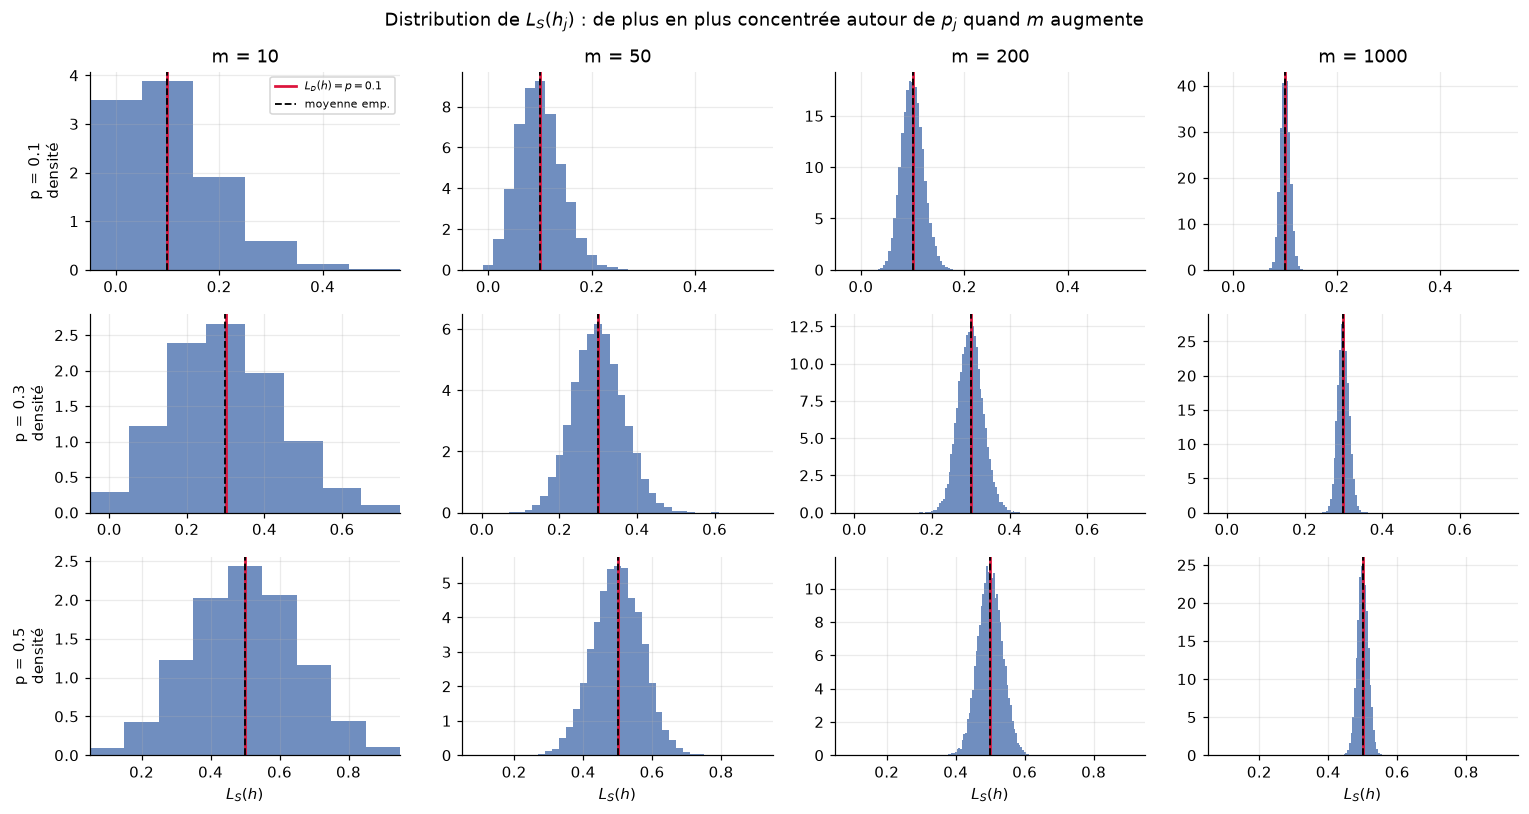

In [5]:
# Histogrammes de L_S(h_j) pour chaque p et chaque m
fig, axes = plt.subplots(len(P_LIST), len(M_LIST), figsize=(14, 7.5), sharex="row")
for i, p in enumerate(P_LIST):
    for j, m in enumerate(M_LIST):
        ax = axes[i, j]
        ls = samples[(p, m)]
        # Pour m grand, on regroupe k valeurs voisines par barre
        k = max(1, round(m / 200))
        bins = (np.arange(0, m + k, k) - 0.5) / m
        ax.hist(ls, bins=bins, density=True, color="#4C72B0", alpha=0.8)
        ax.axvline(p, color="crimson", lw=1.8, label=f"$L_D(h)=p={p}$")
        ax.axvline(ls.mean(), color="black", ls="--", lw=1.2, label="moyenne emp.")
        ax.set_xlim(max(-0.05, p - 0.45), min(1.05, p + 0.45))
        if i == 0: ax.set_title(f"m = {m}")
        if j == 0: ax.set_ylabel(f"p = {p}\ndensité")
        if i == len(P_LIST) - 1: ax.set_xlabel(r"$L_S(h)$")
        if i == 0 and j == 0: ax.legend(fontsize=7)
fig.suptitle(r"Distribution de $L_S(h_j)$ : de plus en plus concentrée autour de $p_j$ quand $m$ augmente")
fig.tight_layout()
plt.show()

**INTERPRETATION**

Les histogrammes montrent d'abord que la mesure est juste en moyenne : la ligne pointillée noire (la moyenne des $L_S(h)$ obtenus) tombe sur la ligne rouge ($p$), quelle que soit la taille de $m$. Pourtant, un échantillon pris seul peut se tromper. Avec $m=10$, les valeurs sont très étalées : on peut mesurer 0.1 alors que le vrai risque est 0.3.

Quand $m$ augmente, les histogrammes se resserrent autour de $p$. On voit aussi que la dispersion est la plus grande pour $p=0.5$ : une hypothèse qui se trompe une fois sur deux est la plus imprévisible, alors qu'une hypothèse qui se trompe rarement donne des mesures plus régulières.

On peut conclure que plus on a de données, plus la mesure est fiable.

## Tâche 2 : Écart entre le risque empirique et le risque réel

On estime la probabilité que l'écart $|L_S(h)-L_D(h)|$ dépasse $\epsilon$, et on la compare à la borne de Hoeffding, qui garantit :
$$\Pr[\,|L_S(h)-L_D(h)|>\epsilon\,]\le 2e^{-2m\epsilon^2}.$$

Cette formule dit que la probabilité de se tromper de plus de $\epsilon$ est au plus $2e^{-2m\epsilon^2}$, et qu'elle diminue très vite quand $m$ augmente.

On choisit $\epsilon=0.1$ (un écart de 10 points est assez petit pour compter), $m$ de 5 à 500 pour voir à partir de quand la borne devient utile, 100 000 répétitions pour mesurer des probabilités très petites, et les mêmes $p$ qu'à la tâche 1 pour voir si le niveau de risque change quelque chose.

In [6]:
EPS = 0.1
M_GRID = np.unique(np.round(np.geomspace(5, 500, 25)).astype(int))
N_REP_2 = 100_000
TOL = 1e-12

def hoeffding_single(m, eps):
    # Borne de Hoeffding pour une hypothèse
    return 2 * np.exp(-2 * m * eps**2)

def prob_deviation(p, m, eps, n_rep, rng):
    # Estimation Monte-Carlo de Pr[|L_S(h) - p| > eps].
    ls = rng.binomial(m, p, size=n_rep) / m
    return np.mean(np.abs(ls - p) > eps + TOL)

results_task2 = {}
for p in P_LIST:
    emp = np.array([prob_deviation(p, m, EPS, N_REP_2, rng) for m in M_GRID])
    bound = np.minimum(1.0, hoeffding_single(M_GRID, EPS))   # une proba ne dépasse jamais 1
    results_task2[p] = (emp, bound)


In [7]:
rows = []
for p in P_LIST:
    emp, bound = results_task2[p]
    for m_target in [10, 50, 100, 200, 400]:
        i = np.abs(M_GRID - m_target).argmin()      # valeur de la grille la plus proche
        rows.append([p, M_GRID[i], fmt_prob(emp[i], N_REP_2), fmt(bound[i]),
                     f"{bound[i] / emp[i]:.1f}" if emp[i] > 0 else "non calculable"])
show_table("Tâche 2 : probabilité que L_S(h) s'écarte de plus de ε = 0.1 de L_D(h)",
           ["Risque vrai p", "Taille d'échantillon m", "Probabilité mesurée",
            "Borne de Hoeffding", "Borne / mesure"], rows)

**Tâche 2 : probabilité que L_S(h) s'écarte de plus de ε = 0.1 de L_D(h)**

| Risque vrai p | Taille d'échantillon m | Probabilité mesurée | Borne de Hoeffding | Borne / mesure |
|---|---|---|---|---|
| 0.1 | 9 | 0.2243 | 1.0000 | 4.5 |
| 0.1 | 50 | 0.0096 | 0.7358 | 76.7 |
| 0.1 | 108 | 9.8e-04 | 0.2307 | 235.4 |
| 0.1 | 192 | 2.0e-05 | 0.0430 | 2149.4 |
| 0.1 | 413 | 0 (moins de 1 cas sur 100 000) | 5.2e-04 | non calculable |
| 0.3 | 9 | 0.4649 | 1.0000 | 2.2 |
| 0.3 | 50 | 0.0899 | 0.7358 | 8.2 |
| 0.3 | 108 | 0.0204 | 0.2307 | 11.3 |
| 0.3 | 192 | 0.0025 | 0.0430 | 17.3 |
| 0.3 | 413 | 1.0e-05 | 5.2e-04 | 51.7 |
| 0.5 | 9 | 0.5118 | 1.0000 | 2.0 |
| 0.5 | 50 | 0.1173 | 0.7358 | 6.3 |
| 0.5 | 108 | 0.0429 | 0.2307 | 5.4 |
| 0.5 | 192 | 0.0047 | 0.0430 | 9.1 |
| 0.5 | 413 | 6.0e-05 | 5.2e-04 | 8.6 |

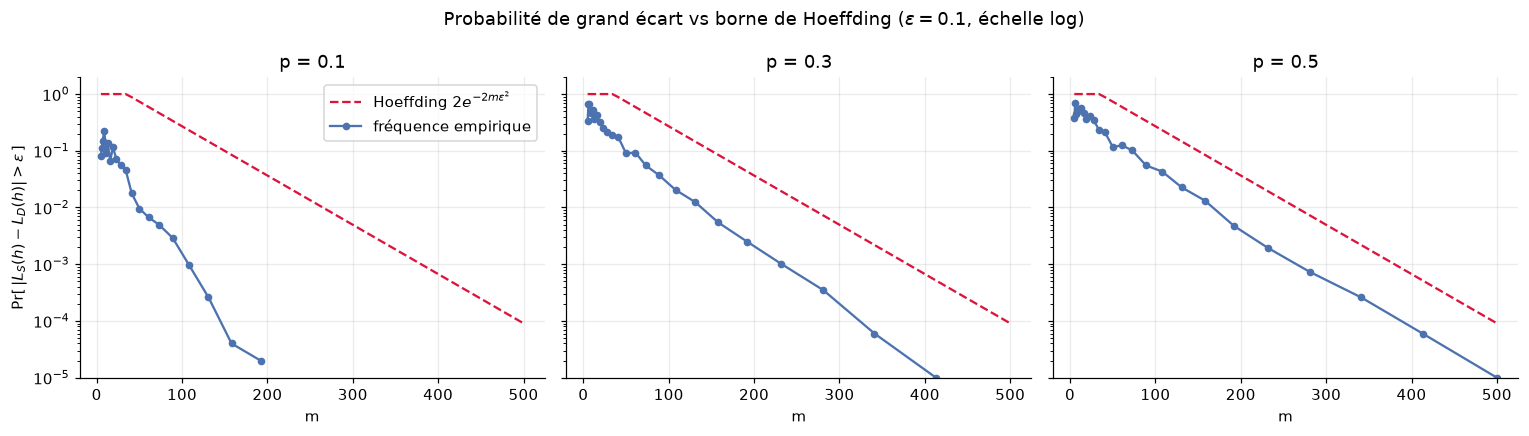

In [8]:
fig, axes = plt.subplots(1, len(P_LIST), figsize=(14, 4), sharey=True)
for ax, p in zip(axes, P_LIST):
    emp, bound = results_task2[p]
    ax.semilogy(M_GRID, bound, "--", color="crimson", label=r"Hoeffding $2e^{-2m\epsilon^2}$")
    ax.semilogy(M_GRID, np.where(emp > 0, emp, np.nan), "o-", color="#4C72B0", ms=4, label="fréquence empirique")
    ax.set_title(f"p = {p}")
    ax.set_xlabel("m")
    ax.set_ylim(1e-5, 2)
axes[0].set_ylabel(r"$\Pr[\,|L_S(h)-L_D(h)|>\epsilon\,]$")
axes[0].legend()
fig.suptitle(rf"Probabilité de grand écart vs borne de Hoeffding ($\epsilon={EPS}$, échelle log)")
fig.tight_layout()
plt.show()

**INTERPRETATION**

La courbe bleue (la probabilité mesurée) est toujours sous la ligne rouge (la borne de Hoeffding), pour toutes les valeurs de $m$ et de $p$. La borne est donc bien respectée.

En revanche, elle est loin de la réalité : elle est de 2 à plus de 2000 fois plus grande que la probabilité mesurée. C'est normal, car Hoeffding doit être vraie pour n'importe quelle hypothèse, et elle ne tient pas compte du fait qu'une hypothèse qui se trompe rarement ($p=0.1$) est plus régulière. C'est pourquoi la borne est la plus proche de la réalité pour $p=0.5$, et la plus éloignée pour $p=0.1$.

Pour $p=0.1$ et $m$ supérieur à environ 200, la probabilité mesurée est nulle : sur 100 000 tirages, aucun n'a dépassé $\epsilon$. Cela veut dire que la probabilité est trop petite pour être vue, pas qu'elle est nulle.

## Tâche 3 : D'une hypothèse à la convergence uniforme

On considère maintenant une classe de $K=100$ hypothèses $h_1,\dots,h_K$ en même temps. Pour chaque échantillon, on regarde le plus grand écart entre risque empirique et risque vrai :
$$\Delta_S=\max_{h\in\mathcal H}|L_S(h)-L_D(h)|.$$
Si $\Delta_S\le\epsilon$, l'échantillon est $\epsilon$-représentatif : toutes les hypothèses sont bien mesurées d'un coup, et c'est ce qui rend l'ERM fiable. On estime $\Pr[\Delta_S>\epsilon]$ et on la compare à la borne obtenue avec la borne de l'union :
$$\Pr[\Delta_S>\epsilon]\le 2|\mathcal H|e^{-2m\epsilon^2}.$$

On prend $K=100$ hypothèses dont les risques vrais sont tirés au hasard entre 0 et 1, pour avoir un mélange d'hypothèses bonnes et mauvaises.

On garde $\epsilon=0.1$ et la même grille de $m$ qu'à la tâche 2, pour pouvoir comparer directement avec le cas d'une seule hypothèse. 

On utilise 10 000 répétitions, ce qui est moins qu'avant car chaque répétition simule maintenant $K$ hypothèses.

Enfin, comme demandé dans l'énoncé, les $K$ nombres d'erreurs sont simulés indépendamment les uns des autres. Dans un vrai problème, des hypothèses proches font les mêmes erreurs, donc elles ne sont pas indépendantes.

In [9]:
K = 100
N_REP_UC = 10_000
p_h = rng.uniform(0, 1, size=K)    # risques vrais des K hypothèses

def prob_max_deviation(p_vec, m, eps, n_rep, rng):
    E = rng.binomial(m, p_vec, size=(n_rep, len(p_vec)))   # erreurs de chaque hypothèse (indépendantes)
    delta = np.abs(E / m - p_vec).max(axis=1)
    return np.mean(delta > eps + TOL)

def union_bound(m, eps, K):
    return np.minimum(1.0, 2 * K * np.exp(-2 * m * eps**2))

emp_uc = np.array([prob_max_deviation(p_h, m, EPS, N_REP_UC, rng) for m in M_GRID])
# Pour comparer : une seule hypothèse (celle de risque le plus proche de 0.5, la plus variable)
j_worst = np.argmin(np.abs(p_h - 0.5))
emp_one = np.array([prob_deviation(p_h[j_worst], m, EPS, N_REP_UC, rng) for m in M_GRID])

In [10]:
rows = []
for m_target in [50, 100, 200, 300, 400]:
    i = np.abs(M_GRID - m_target).argmin()
    rows.append([M_GRID[i], fmt_prob(emp_one[i], N_REP_UC), fmt_prob(emp_uc[i], N_REP_UC),
                 fmt(union_bound(M_GRID[i], EPS, K))])
show_table(f"Tâche 3 : probabilité d'un écart supérieur à ε = {EPS}",
           ["Taille d'échantillon m", "Une seule hypothèse (mesure)",
            f"Toute la classe de {K} hypothèses (mesure)", f"Borne de l'union 2K·exp(−2mε²), avec K = {K}"], rows)

**Tâche 3 : probabilité d'un écart supérieur à ε = 0.1**

| Taille d'échantillon m | Une seule hypothèse (mesure) | Toute la classe de 100 hypothèses (mesure) | Borne de l'union 2K·exp(−2mε²), avec K = 100 |
|---|---|---|---|
| 50 | 0.1591 | 1.0000 | 1.0000 |
| 108 | 0.0405 | 0.8171 | 1.0000 |
| 192 | 0.0063 | 0.1764 | 1.0000 |
| 281 | 0.0012 | 0.0248 | 0.7249 |
| 413 | 0 (moins de 1 cas sur 10 000) | 0.0016 | 0.0517 |

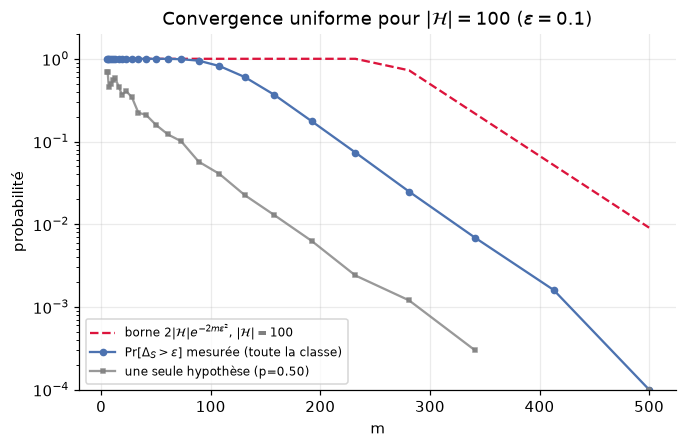

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(M_GRID, union_bound(M_GRID, EPS, K), "--", color="crimson", label=rf"borne $2|\mathcal{{H}}|e^{{-2m\epsilon^2}}$, $|\mathcal{{H}}|={K}$")
ax.semilogy(M_GRID, np.where(emp_uc > 0, emp_uc, np.nan), "o-", color="#4C72B0", ms=4, label=r"$\Pr[\Delta_S>\epsilon]$ mesurée (toute la classe)")
ax.semilogy(M_GRID, np.where(emp_one > 0, emp_one, np.nan), "s-", color="gray", ms=3, alpha=0.8, label=f"une seule hypothèse (p={p_h[j_worst]:.2f})")
ax.set_xlabel("m")
ax.set_ylabel("probabilité")
ax.set_ylim(1e-4, 2)
ax.set_title(rf"Convergence uniforme pour $|\mathcal{{H}}|={K}$ ($\epsilon={EPS}$)")
ax.legend(fontsize=8)
plt.show()

**INTERPRETATION**

La courbe bleue est la probabilité qu'au moins une des 100 hypothèses soit mal mesurée de plus de $\epsilon$. Elle reste sous la borne théorique pour toutes les valeurs de $m$, donc la borne de l'union est bien respectée.

Cette probabilité est plus élevée que celle d'une seule hypothèse (courbe grise), et elle met plus longtemps à descendre : elle reste proche de 1 jusqu'à $m\approx 80$, alors qu'une seule hypothèse a déjà une probabilité d'échec inférieure à 0.2. C'est logique : pour que l'échantillon soit représentatif, il faut qu'aucune des 100 hypothèses ne se trompe, alors qu'il suffit qu'une seule soit mal mesurée pour que ce soit raté. C'est pour cela que la convergence uniforme demande plus de données qu'une simple estimation pour une hypothèse.

La borne reste au-dessus de la courbe mesurée avec un écart qui ne se referme pas : pour $m\approx 400$, elle est environ 30 fois trop grande. Elle est large, comme pour une seule hypothèse.

On peut conclure qu'il faut contrôler toutes les hypothèses à la fois, ce qui demande plus de données que pour une seule.

## Tâche 4 : Effet de la taille de la classe d'hypothèses

On refait la même expérience pour $|\mathcal H|\in\{5, 10, 50, 100, 500\}$, avec $\epsilon=0.1$ fixé.

Ces valeurs sont celles de l'énoncé : elles vont d'une petite à une grande classe. Les classes sont emboîtées (la classe de 5 hypothèses est formée des 5 premières de la classe de 500), pour que seule la taille change d'une courbe à l'autre.

In [12]:
K_LIST = [5, 10, 50, 100, 500]
p_all = rng.uniform(0, 1, size=max(K_LIST))   # classes emboîtées

emp_by_K = {}
for Kc in K_LIST:
    emp_by_K[Kc] = np.array([prob_max_deviation(p_all[:Kc], m, EPS, N_REP_UC, rng) for m in M_GRID])

In [13]:
rows = []
for m_target in [50, 100, 200, 300, 400]:
    i = np.abs(M_GRID - m_target).argmin()
    rows.append([M_GRID[i]] + [fmt_prob(emp_by_K[Kc][i], N_REP_UC) for Kc in K_LIST])
show_table(f"Tâche 4 : probabilité mesurée que le plus grand écart dépasse ε = {EPS}, selon la taille de la classe",
           ["Taille d'échantillon m"] + [f"Classe de {Kc} hypothèses" for Kc in K_LIST], rows)

**Tâche 4 : probabilité mesurée que le plus grand écart dépasse ε = 0.1, selon la taille de la classe**

| Taille d'échantillon m | Classe de 5 hypothèses | Classe de 10 hypothèses | Classe de 50 hypothèses | Classe de 100 hypothèses | Classe de 500 hypothèses |
|---|---|---|---|---|---|
| 50 | 0.2313 | 0.5296 | 0.9901 | 0.9999 | 1.0000 |
| 108 | 0.0327 | 0.1058 | 0.5831 | 0.8135 | 1.0000 |
| 192 | 0.0032 | 0.0129 | 0.0879 | 0.1749 | 0.6310 |
| 281 | 3.0e-04 | 0.0018 | 0.0104 | 0.0233 | 0.1157 |
| 413 | 0 (moins de 1 cas sur 10 000) | 1.0e-04 | 4.0e-04 | 8.0e-04 | 0.0079 |

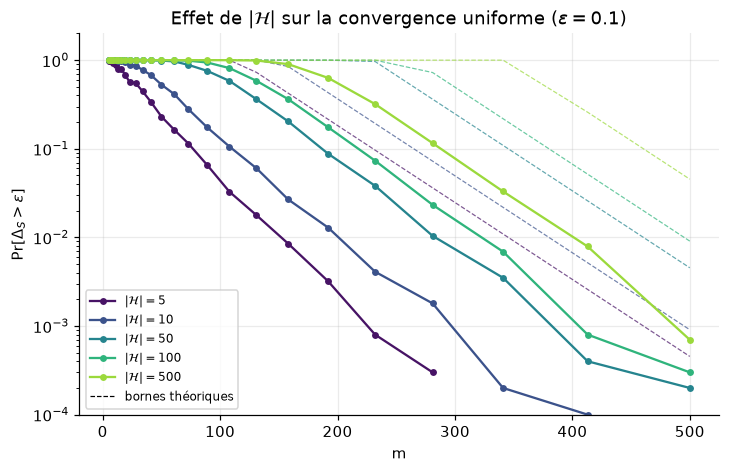

In [14]:
colors = plt.cm.viridis(np.linspace(0.05, 0.85, len(K_LIST)))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for Kc, col in zip(K_LIST, colors):
    e = emp_by_K[Kc]
    ax.semilogy(M_GRID, np.where(e > 0, e, np.nan), "o-", color=col, ms=3.5, label=rf"$|\mathcal{{H}}|={Kc}$")
    ax.semilogy(M_GRID, union_bound(M_GRID, EPS, Kc), "--", color=col, lw=0.8, alpha=0.7)
ax.plot([], [], "k--", lw=0.8, label="bornes théoriques")
ax.set_xlabel("m")
ax.set_ylabel(r"$\Pr[\Delta_S>\epsilon]$")
ax.set_ylim(1e-4, 2)
ax.set_title(rf"Effet de $|\mathcal{{H}}|$ sur la convergence uniforme ($\epsilon={EPS}$)")
ax.legend(fontsize=8)
plt.show()

**INTERPRETATION**

Plus la classe est grande, plus les courbes sont décalées vers la droite : à $m$ égal, la probabilité qu'au moins une hypothèse soit mal mesurée augmente avec $|\mathcal H|$. Une classe plus grande demande donc en général plus de données pour obtenir la même garantie. C'est logique, car on a plus d'occasions qu'une des hypothèses soit mal mesurée par hasard.

En revanche, le décalage est faible par rapport à l'écart de taille. Passer de 5 à 500 hypothèses multiplie la taille de la classe par 100, mais les courbes se décalent seulement de quelques centaines d'exemples. C'est ce que prévoit la borne, car $|\mathcal H|$ n'apparaît que dans $\log|\mathcal H|$ : donc multiplier la taille de la classe par 10 revient à ajouter environ $\log(10)/(2\epsilon^2)\approx 115$ exemples, et non à multiplier simplement $m$ par 10.

On peut conclure qu'une classe plus grande demande plus de données, mais seulement de façon logarithmique.

## Tâche 5 : Complexité des échantillons expérimentaux

On fixe $\epsilon=0.1$ et $\delta=0.05$ : on veut que $\Pr[\Delta_S>\epsilon]\le 5\,\%$. Pour chaque taille de classe, on cherche le plus petit $m$ testé pour lequel c'est vrai, et on le compare au $m$ suffisant de la théorie :
$$m\ge\frac{\log(2|\mathcal H|/\delta)}{2\epsilon^2}.$$

On teste $m$ de 10 à 600 par pas de 10 : c'est assez fin pour comparer à la théorie, et le résultat est donc connu à 10 près.

**Tâche 5 : plus petite taille d'échantillon m telle que la probabilité d'un écart supérieur à ε = 0.1 soit au plus δ = 0.05**

| Nombre d'hypothèses K | m expérimental (plus petit m testé) | m théorique log(2K/δ) / (2ε²) | Rapport théorie / expérience |
|---|---|---|---|
| 5 | 100 | 265 | 2.6 |
| 10 | 140 | 300 | 2.1 |
| 50 | 220 | 381 | 1.7 |
| 100 | 250 | 415 | 1.7 |
| 500 | 320 | 496 | 1.6 |

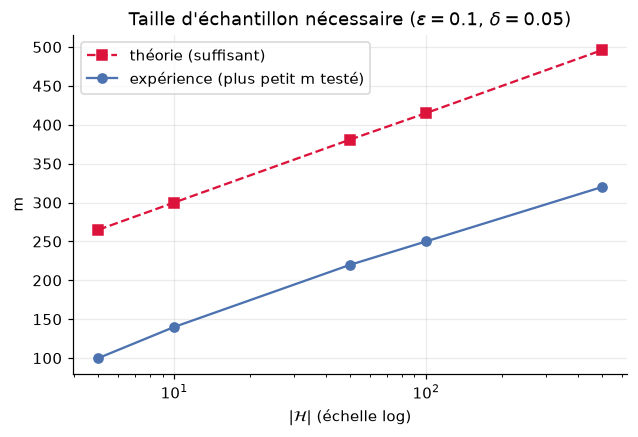

In [15]:
DELTA = 0.05
M_SEARCH = np.arange(10, 601, 10)

def theory_m(K, eps, delta):
    # m suffisant d'après la borne de l'union
    return int(np.ceil(np.log(2 * K / delta) / (2 * eps**2)))

def smallest_m(p_vec, eps, delta, m_values, n_rep, rng):
    # Plus petit m testé tel que Pr[Delta_S > eps] <= delta
    for m in m_values:
        if prob_max_deviation(p_vec, m, eps, n_rep, rng) <= delta:
            return int(m)
    return None

m_exp = {Kc: smallest_m(p_all[:Kc], EPS, DELTA, M_SEARCH, N_REP_UC, rng) for Kc in K_LIST}
m_th  = {Kc: theory_m(Kc, EPS, DELTA) for Kc in K_LIST}

show_table(f"Tâche 5 : plus petite taille d'échantillon m telle que la probabilité d'un écart supérieur à ε = {EPS} soit au plus δ = {DELTA}",
           ["Nombre d'hypothèses K", "m expérimental (plus petit m testé)", "m théorique log(2K/δ) / (2ε²)",
            "Rapport théorie / expérience"],
           [[Kc, m_exp[Kc], m_th[Kc], f"{m_th[Kc] / m_exp[Kc]:.1f}"] for Kc in K_LIST])

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(K_LIST, [m_th[Kc] for Kc in K_LIST], "s--", color="crimson", label="théorie (suffisant)")
ax.plot(K_LIST, [m_exp[Kc] for Kc in K_LIST], "o-", color="#4C72B0", label="expérience (plus petit m testé)")
ax.set_xscale("log")
ax.set_xlabel(r"$|\mathcal{H}|$ (échelle log)")
ax.set_ylabel("m")
ax.set_title(rf"Taille d'échantillon nécessaire ($\epsilon={EPS}$, $\delta={DELTA}$)")
ax.legend()
plt.show()

**INTERPRETATION**

Pour chaque taille de classe, le $m$ expérimental est toujours plus petit que le $m$ théorique. La théorie ne se trompe donc jamais, mais elle demande de 1.6 à 2.6 fois plus d'exemples qu'il n'en faut. Cela confirme que la formule donne un $m$ suffisant, pas le plus petit $m$ possible : elle repose sur Hoeffding et sur la borne de l'union, qui sont toutes les deux écrites pour le pire cas.

On remarque que l'écart entre théorie et expérience reste à peu près constant, quel que soit $|\mathcal H|$. Le rapport diminue donc quand la classe grandit, mais seulement parce que $m$ augmente. Les deux courbes sont à peu près parallèles sur l'échelle logarithmique : la façon dont $m$ croît avec $\log|\mathcal H|$ est bien celle prévue par la théorie.

# Partie II : Simulation du No-Free-Lunch

On considère un domaine fini $\mathcal X=\{1,\dots,N\}$ avec la loi uniforme. À chaque répétition, on tire une nouvelle cible $f:\mathcal X\to\{0,1\}$ en choisissant $f(x)$ au hasard (pile ou face) indépendamment pour chaque $x$, donc chaque répétition est un nouveau problème d'apprentissage. L'apprenant reçoit $m$ exemples tirés uniformément avec remise et applique une règle de mémorisation : si $x$ a été vu, il prédit son label ; sinon, il prédit 0.

## Tâche 6 : Entrées vues et non vues

Pour plusieurs valeurs de $N$ et de $m$, on tire un échantillon et on calcule la fraction des $N$ entrées qui n'ont jamais été tirées. On compare la moyenne obtenue à la probabilité théorique qu'un point fixé $x$ ne soit jamais tiré :
$$\Pr[x\text{ n'est pas vu}]=\left(1-\frac1N\right)^m.$$

On prend $N\in\{10,50,100\}$ (un petit, un moyen et un grand domaine) et $m$ de 0 à 300 par pas de 10, pour voir la fraction évoluer de « rien n'a été vu » à « presque tout a été vu ». Avec 10 000 répétitions, les moyennes sont stables.

In [16]:
N_LIST = [10, 50, 100]                 # tailles du domaine
M_NFL = np.arange(0, 301, 10)          # tailles d'échantillon (m = 0 : aucun exemple)
N_REP_NFL = 10_000

def simulate_random_targets(N, m, n_rep, rng, unseen_rule="zero", q=0.5):
    # Retourne (fraction d'entrées non vues, vrai risque L_D(A(S))) pour chaque répétition.
    # unseen_rule : prédiction sur les entrées non vues
    # q : probabilité que f(x) = 1
    draws = rng.integers(0, N, size=(n_rep, m)) # les m entrées de chaque échantillon
    seen = np.zeros((n_rep, N), dtype=bool)
    seen[np.arange(n_rep)[:, None], draws] = True # entrées apparues dans l'échantillon
    f = (rng.random((n_rep, N)) < q).astype(int)                      
    if unseen_rule == "zero":
        unseen_pred = np.zeros((n_rep, N), dtype=int)
    elif unseen_rule == "one":
        unseen_pred = np.ones((n_rep, N), dtype=int)
    else:
        unseen_pred = rng.integers(0, 2, size=(n_rep, N))
    pred = np.where(seen, f, unseen_pred)    # entrée vue : on connaît son label ; sinon on applique la règle
    risk = (pred != f).mean(axis=1)          # L_D(A(S)) sur tout le domaine (loi uniforme)
    unseen_frac = 1 - seen.mean(axis=1)
    return unseen_frac, risk

unseen_emp = {N: np.array([simulate_random_targets(N, m, N_REP_NFL, rng)[0].mean() for m in M_NFL]) for N in N_LIST}

In [17]:
rows = []
for N in N_LIST:
    for m in [10, 50, 100, 200]:
        i = list(M_NFL).index(m)
        rows.append([N, m, fmt(unseen_emp[N][i]), fmt((1 - 1 / N) ** m)])
show_table("Tâche 6 : fraction des N entrées qui n'ont jamais été tirées",
           ["Taille du domaine N", "Taille d'échantillon m", "Fraction non vue (simulation)",
            "Fraction non vue (théorie (1−1/N)^m)"], rows)

**Tâche 6 : fraction des N entrées qui n'ont jamais été tirées**

| Taille du domaine N | Taille d'échantillon m | Fraction non vue (simulation) | Fraction non vue (théorie (1−1/N)^m) |
|---|---|---|---|
| 10 | 10 | 0.3487 | 0.3487 |
| 10 | 50 | 0.0051 | 0.0052 |
| 10 | 100 | 1.0e-05 | 2.7e-05 |
| 10 | 200 | 0 | 7.1e-10 |
| 50 | 10 | 0.8171 | 0.8171 |
| 50 | 50 | 0.3637 | 0.3642 |
| 50 | 100 | 0.1320 | 0.1326 |
| 50 | 200 | 0.0178 | 0.0176 |
| 100 | 10 | 0.9043 | 0.9044 |
| 100 | 50 | 0.6048 | 0.6050 |
| 100 | 100 | 0.3663 | 0.3660 |
| 100 | 200 | 0.1345 | 0.1340 |

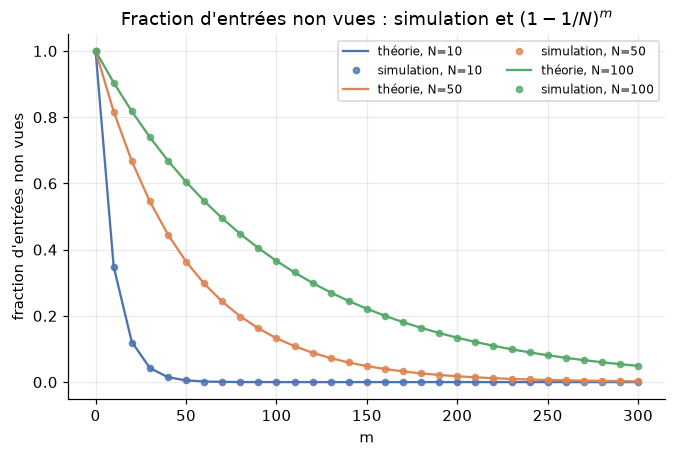

écart maximal simulation - théorie : 0.0022


In [18]:
colors_N = {10: "#4C72B0", 50: "#DD8452", 100: "#55A868"}
fig, ax = plt.subplots(figsize=(7, 4.3))
for N in N_LIST:
    ax.plot(M_NFL, (1 - 1 / N) ** M_NFL, "-", color=colors_N[N], lw=1.5, label=f"théorie, N={N}")
    ax.plot(M_NFL, unseen_emp[N], "o", color=colors_N[N], ms=4, alpha=0.8, label=f"simulation, N={N}")
ax.set_xlabel("m")
ax.set_ylabel("fraction d'entrées non vues")
ax.set_title(r"Fraction d'entrées non vues : simulation et $(1-1/N)^m$")
ax.legend(fontsize=8, ncol=2)
plt.show()

print("écart maximal simulation - théorie :",
      max(np.max(np.abs(unseen_emp[N] - (1 - 1 / N) ** M_NFL)) for N in N_LIST).round(4))

**INTERPRETATION**

Les points de la simulation tombent sur les courbes théoriques $(1-1/N)^m$ : la formule décrit bien la fraction d'entrées non vues. Cette fraction diminue lentement : pour $m=N$, il reste environ 37 % des entrées jamais vues, et avec $N=100$ il faut encore $m=300$ exemples pour descendre à 5 %.

C'est aussi l'espérance de la fraction. La fraction non vue est la moyenne, sur les $N$ entrées, de « cette entrée n'a pas été tirée », et chaque entrée a la même probabilité $(1-1/N)^m$ de ne pas être tirée. Une moyenne de $N$ quantités qui ont toutes la même espérance a cette même espérance.

On peut conclure que tant que $m$ est petit devant $N$, une grande partie du domaine n'est jamais observée.

## Tâche 7 : Erreur sur les entrées non vues

On calcule le vrai risque de l'apprenant sur tout le domaine :
$$L_D(A(S))=\frac1N\sum_{x\in\mathcal X}\mathbf 1[A(S)(x)\neq f(x)].$$
On répète sur beaucoup de cibles aléatoires et d'échantillons, et on compare la moyenne à la valeur théorique $\frac12\left(1-\frac1N\right)^m$. On garde les mêmes $N$ et $m$ qu'à la tâche 6, pour pouvoir comparer les deux résultats.

**D'où vient cette valeur.** L'apprenant ne se trompe jamais sur une entrée vue. Sur une entrée non vue, il prédit 0 alors que le vrai label est un pile ou face : il se trompe une fois sur deux. Une entrée est non vue avec probabilité $(1-1/N)^m$, donc chaque entrée est mal prédite avec probabilité $\frac12(1-1/N)^m$, et le risque, qui est la moyenne sur les entrées, a la même espérance.

In [19]:
risk_emp = {N: np.array([simulate_random_targets(N, m, N_REP_NFL, rng)[1].mean() for m in M_NFL]) for N in N_LIST}

In [20]:
rows = []
for N in N_LIST:
    for m in [10, 50, 100, 200]:
        i = list(M_NFL).index(m)
        rows.append([N, m, fmt(risk_emp[N][i]), fmt(0.5 * (1 - 1 / N) ** m)])
show_table("Tâche 7 : vrai risque moyen de l'apprenant sur une cible aléatoire",
           ["Taille du domaine N", "Taille d'échantillon m", "Risque moyen (simulation)",
            "Risque moyen (théorie ½(1−1/N)^m)"], rows)

**Tâche 7 : vrai risque moyen de l'apprenant sur une cible aléatoire**

| Taille du domaine N | Taille d'échantillon m | Risque moyen (simulation) | Risque moyen (théorie ½(1−1/N)^m) |
|---|---|---|---|
| 10 | 10 | 0.1750 | 0.1743 |
| 10 | 50 | 0.0025 | 0.0026 |
| 10 | 100 | 0 | 1.3e-05 |
| 10 | 200 | 0 | 3.5e-10 |
| 50 | 10 | 0.4087 | 0.4085 |
| 50 | 50 | 0.1822 | 0.1821 |
| 50 | 100 | 0.0668 | 0.0663 |
| 50 | 200 | 0.0086 | 0.0088 |
| 100 | 10 | 0.4525 | 0.4522 |
| 100 | 50 | 0.3030 | 0.3025 |
| 100 | 100 | 0.1830 | 0.1830 |
| 100 | 200 | 0.0671 | 0.0670 |

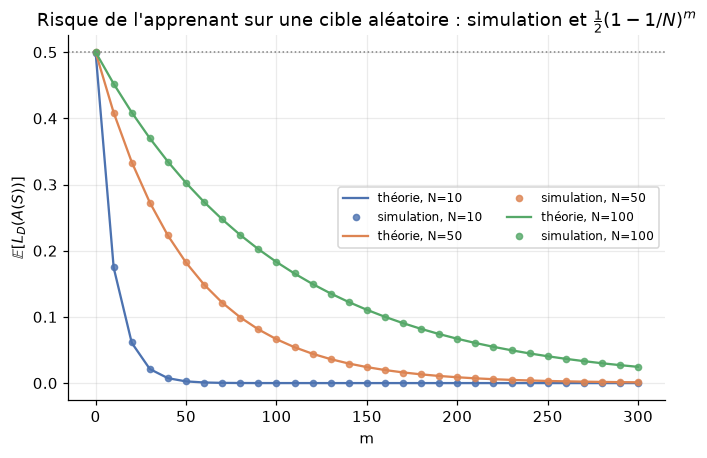

écart maximal simulation - théorie : 0.0013


In [21]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for N in N_LIST:
    ax.plot(M_NFL, 0.5 * (1 - 1 / N) ** M_NFL, "-", color=colors_N[N], lw=1.5, label=f"théorie, N={N}")
    ax.plot(M_NFL, risk_emp[N], "o", color=colors_N[N], ms=4, alpha=0.8, label=f"simulation, N={N}")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("m")
ax.set_ylabel(r"$\mathbb{E}[L_D(A(S))]$")
ax.set_title(r"Risque de l'apprenant sur une cible aléatoire : simulation et $\frac{1}{2}(1-1/N)^m$")
ax.legend(fontsize=8, ncol=2)
plt.show()

print("écart maximal simulation - théorie :",
      max(np.max(np.abs(risk_emp[N] - 0.5 * (1 - 1 / N) ** M_NFL)) for N in N_LIST).round(4))

**INTERPRETATION**

La simulation confirme la valeur théorique $\frac12(1-1/N)^m$. Sans exemple, le risque vaut 0.5 : l'apprenant devine au hasard. Il ne diminue ensuite que parce que moins d'entrées restent non vues : sur une entrée vue l'apprenant a raison, et sur une entrée non vue il se trompe une fois sur deux.

Les exemples ne l'aident donc pas à prédire les entrées qu'il n'a pas vues. Pour $N=50$, il faut encore 100 exemples pour passer sous 7 % d'erreur, soit deux fois la taille du domaine : l'apprenant ne fait que mémoriser.

On peut conclure que, pour une cible aléatoire, l'erreur est la moitié de la fraction d'entrées non vues, et qu'on ne peut pas faire mieux avec les seuls exemples.

## Tâche 8 : Changer la prédiction sur les entrées non vues

On compare trois règles pour les entrées non vues : toujours prédire 0, toujours prédire 1, ou prédire un label aléatoire. Les entrées vues sont toujours prédites avec leur label observé. On calcule d'abord les risques moyens quand les cibles sont complètement aléatoires ($\Pr[f(x)=1]=\tfrac12$), pour $N=50$.

Pour mieux voir le lien avec le No-Free-Lunch, on refait ensuite la même comparaison avec des cibles qui ne sont plus tirées à pile ou face : chaque $f(x)$ vaut 1 avec probabilité $q$, pour $q=0.1$ (cibles surtout égales à 0), $q=0.5$ et $q=0.9$ (cibles surtout égales à 1).

On prend $N=50$ et 10 000 répétitions. Pour les cibles biaisées, on fixe $m=20$ : il reste alors environ 67 % d'entrées non vues, et c'est sur elles que les règles diffèrent.

In [22]:
N8 = 50
rules = {"toujours 0": "zero", "toujours 1": "one", "label aléatoire": "random"}
rule_colors = {"toujours 0": "#4C72B0", "toujours 1": "#DD8452", "label aléatoire": "#55A868"}
rule_markers = {"toujours 0": "o", "toujours 1": "s", "label aléatoire": "^"}

# (a) cibles complètement aléatoires
risk_rules = {name: np.array([simulate_random_targets(N8, m, N_REP_NFL, rng, unseen_rule=r)[1].mean() for m in M_NFL])
              for name, r in rules.items()}

# (b) cibles biaisées : f(x) = 1 avec probabilité q
Q_LIST = [0.1, 0.5, 0.9]
M_BIAS = 20   # un échantillon petit devant N, pour qu'il reste beaucoup d'entrées non vues
risk_bias = {q: {name: simulate_random_targets(N8, M_BIAS, N_REP_NFL, rng, unseen_rule=r, q=q)[1].mean()
                 for name, r in rules.items()} for q in Q_LIST}

In [23]:
rows = []
for m in [0, 20, 50, 100, 200]:
    i = list(M_NFL).index(m) if m in M_NFL else None
    if i is None:
        continue
    rows.append([m] + [fmt(risk_rules[name][i]) for name in rules] + [fmt(0.5 * (1 - 1 / N8) ** m)])
show_table(f"Tâche 8 (a) : risque moyen selon la règle sur les entrées non vues, cibles complètement aléatoires (N = {N8})",
           ["Taille d'échantillon m"] + [f"Règle : {name}" for name in rules] + ["Théorie ½(1−1/N)^m"], rows)

show_table(f"Tâche 8 (b) : risque moyen selon la règle, cibles biaisées (m = {M_BIAS}, N = {N8})",
           ["Probabilité q que f(x) = 1"] + [f"Règle : {name}" for name in rules],
           [[q] + [fmt(risk_bias[q][name]) for name in rules] for q in Q_LIST])

**Tâche 8 (a) : risque moyen selon la règle sur les entrées non vues, cibles complètement aléatoires (N = 50)**

| Taille d'échantillon m | Règle : toujours 0 | Règle : toujours 1 | Règle : label aléatoire | Théorie ½(1−1/N)^m |
|---|---|---|---|---|
| 0 | 0.4989 | 0.5012 | 0.4996 | 0.5000 |
| 20 | 0.3331 | 0.3337 | 0.3336 | 0.3338 |
| 50 | 0.1823 | 0.1819 | 0.1824 | 0.1821 |
| 100 | 0.0660 | 0.0658 | 0.0656 | 0.0663 |
| 200 | 0.0089 | 0.0088 | 0.0088 | 0.0088 |

**Tâche 8 (b) : risque moyen selon la règle, cibles biaisées (m = 20, N = 50)**

| Probabilité q que f(x) = 1 | Règle : toujours 0 | Règle : toujours 1 | Règle : label aléatoire |
|---|---|---|---|
| 0.1 | 0.0666 | 0.6010 | 0.3344 |
| 0.5 | 0.3346 | 0.3340 | 0.3338 |
| 0.9 | 0.6013 | 0.0668 | 0.3340 |

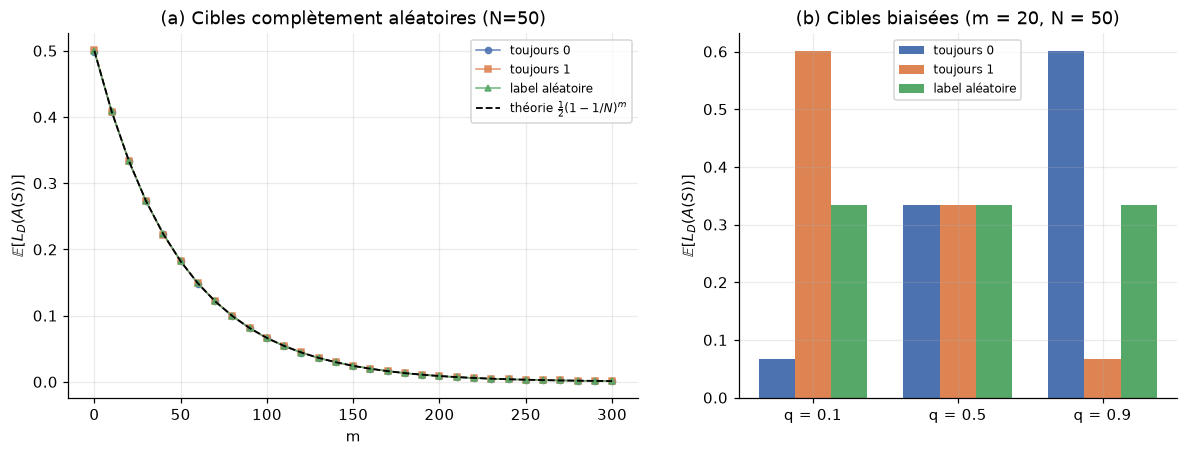

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
for name in rules:
    ax1.plot(M_NFL, risk_rules[name], rule_markers[name] + "-", color=rule_colors[name], ms=4, lw=1, alpha=0.85, label=name)
ax1.plot(M_NFL, 0.5 * (1 - 1 / N8) ** M_NFL, "k--", lw=1.2, label=r"théorie $\frac{1}{2}(1-1/N)^m$")
ax1.set_xlabel("m")
ax1.set_ylabel(r"$\mathbb{E}[L_D(A(S))]$")
ax1.set_title(f"(a) Cibles complètement aléatoires (N={N8})")
ax1.legend(fontsize=8)

width = 0.25
for k, name in enumerate(rules):
    ax2.bar(np.arange(len(Q_LIST)) + (k - 1) * width, [risk_bias[q][name] for q in Q_LIST], width,
            color=rule_colors[name], label=name)
ax2.set_xticks(np.arange(len(Q_LIST)))
ax2.set_xticklabels([f"q = {q}" for q in Q_LIST])
ax2.set_ylabel(r"$\mathbb{E}[L_D(A(S))]$")
ax2.set_title(f"(b) Cibles biaisées (m = {M_BIAS}, N = {N8})")
ax2.legend(fontsize=8)
plt.show()

**INTERPRETATION**

Dans le graphique (a), les trois règles donnent la même courbe, égale à la courbe théorique. Quand la cible est complètement aléatoire, le label d'une entrée non vue est un pile ou face : prédire 0, prédire 1 ou tirer au hasard fait dans tous les cas une erreur une fois sur deux. Aucune règle ne fait mieux que les autres.

Dans le graphique (b), le résultat dépend de la cible. Quand elle vaut surtout 0 ($q=0.1$), « toujours 0 » est la meilleure règle (risque 0.067) et « toujours 1 » la pire (0.601). Pour $q=0.9$ c'est l'inverse, et pour $q=0.5$ les trois règles sont à égalité. La règle « label aléatoire » reste à 0.334 dans tous les cas : elle ne perd jamais beaucoup, mais ne gagne jamais.

On peut conclure qu'une règle n'est meilleure que si elle correspond à une hypothèse sur la cible (ici « la plupart des labels sont 0 »). Sans cette hypothèse, aucune règle ne fait mieux que les autres : c'est le No-Free-Lunch.

# Partie III : Introduction de connaissances a priori

On garde le même domaine $\mathcal X=\{1,\dots,N\}$ avec la loi uniforme, mais la cible est maintenant un seuil
$$f_\theta(x)=\mathbf 1[x>\theta],\qquad \theta\in\{1,\dots,N-1\}\text{ tiré uniformément}.$$
L'apprenant cherche uniquement parmi les seuils $\mathcal H=\{h_t(x)=\mathbf 1[x>t]:t\in\{1,\dots,N-1\}\}$ et prend par ERM un seuil qui fait le moins d'erreurs possible sur l'échantillon. Si plusieurs seuils font autant d'erreurs, on en choisit un au hasard parmi eux.

## Tâche 9 : Apprendre avec un biais inductif adapté

Pour chaque $m$, on tire un seuil cible, un échantillon de taille $m$, on apprend $h_S$ par ERM et on calcule son vrai risque sur tout le domaine :
$$L_D(h_S)=\frac1N\sum_{x\in\mathcal X}\mathbf 1[h_S(x)\neq f_\theta(x)].$$
On répète l'expérience et on estime $\mathbb E[L_D(h_S)]$. On reprend les mêmes $N$ et $m$ que dans la partie II, pour comparer directement avec la mémorisation. On fait 5 000 répétitions au lieu de 10 000 car l'ERM est plus long à calculer, et cela donne déjà des moyennes assez stables.

In [25]:
N_REP_THR = 5_000

def simulate_erm_thresholds(N, m, n_rep, rng, target="threshold"):
    # Retourne le vrai risque L_D(h_S) de chaque répétition.
    xs = np.arange(1, N + 1)
    if target == "threshold":
        theta = rng.integers(1, N, size=n_rep)
        f = (xs[None, :] > theta[:, None]).astype(int)
    else:
        f = rng.integers(0, 2, size=(n_rep, N))

    draws = rng.integers(0, N, size=(n_rep, m))                   
    labels = np.take_along_axis(f, draws, axis=1)              
    rows = np.arange(n_rep)[:, None] * N

    # Nombre d'exemples de l'échantillon, par entrée x : au total et de label 1
    count_all = np.bincount((rows + draws).ravel(), minlength=n_rep * N).reshape(n_rep, N)
    count_one = np.bincount((rows + draws)[labels == 1], minlength=n_rep * N).reshape(n_rep, N)
    count_zero = count_all - count_one

    # Erreurs d'entraînement de h_t pour t = 1..N-1
    cum_zero = np.cumsum(count_zero, axis=1)[:, :N - 1]
    cum_one = np.cumsum(count_one, axis=1)[:, :N - 1]
    train_err = (count_zero.sum(axis=1)[:, None] - cum_zero) + cum_one

    # ERM, avec choix au hasard parmi les seuils à égalité
    t_hat = 1 + np.argmin(train_err + rng.random(train_err.shape) * 0.5, axis=1)

    pred = (xs[None, :] > t_hat[:, None]).astype(int)
    return (pred != f).mean(axis=1)

# Vérification à m = 0
check = simulate_erm_thresholds(50, 0, 20_000, rng).mean()
print(f"m = 0 : risque moyen = {check:.3f} (attendu : 0.327 pour N = 50)")

risk_thr = {N: np.array([simulate_erm_thresholds(N, m, N_REP_THR, rng).mean() for m in M_NFL]) for N in N_LIST}

m = 0 : risque moyen = 0.329 (attendu : 0.327 pour N = 50)


In [26]:
# Comparaison avec la borne du cours dans le cas réalisable
DELTA_THR = 0.05
rows = []
for N in N_LIST:
    for m in [10, 50, 100, 200]:
        risks = simulate_erm_thresholds(N, m, N_REP_THR, rng)
        bound = np.log((N - 1) / DELTA_THR) / m
        rows.append([N, m, fmt(risks.mean()), fmt(np.quantile(risks, 1 - DELTA_THR)), fmt(min(bound, 1.0)),
                     fmt(0.5 * (1 - 1 / N) ** m)])
show_table("Tâche 9 : risque de l'ERM sur les seuils, cible en seuil",
           ["Taille du domaine N", "Taille d'échantillon m", "Risque moyen E[L_D(h_S)]",
            "Risque maximal dans 95 % des cas", "Borne du cours log((N−1)/δ)/m, δ = 0.05",
            "Mémorisation, cible aléatoire (partie II)"], rows)

**Tâche 9 : risque de l'ERM sur les seuils, cible en seuil**

| Taille du domaine N | Taille d'échantillon m | Risque moyen E[L_D(h_S)] | Risque maximal dans 95 % des cas | Borne du cours log((N−1)/δ)/m, δ = 0.05 | Mémorisation, cible aléatoire (partie II) |
|---|---|---|---|---|---|
| 10 | 10 | 0.0378 | 0.2000 | 0.5193 | 0.1743 |
| 10 | 50 | 3.2e-04 | 0 | 0.1039 | 0.0026 |
| 10 | 100 | 0 | 0 | 0.0519 | 1.3e-05 |
| 10 | 200 | 0 | 0 | 0.0260 | 3.5e-10 |
| 50 | 10 | 0.0533 | 0.1600 | 0.6888 | 0.4085 |
| 50 | 50 | 0.0101 | 0.0400 | 0.1378 | 0.1821 |
| 50 | 100 | 0.0029 | 0.0200 | 0.0689 | 0.0663 |
| 50 | 200 | 3.0e-04 | 0 | 0.0344 | 0.0088 |
| 100 | 10 | 0.0548 | 0.1800 | 0.7591 | 0.4522 |
| 100 | 50 | 0.0116 | 0.0400 | 0.1518 | 0.3025 |
| 100 | 100 | 0.0049 | 0.0200 | 0.0759 | 0.1830 |
| 100 | 200 | 0.0015 | 0.0100 | 0.0380 | 0.0670 |

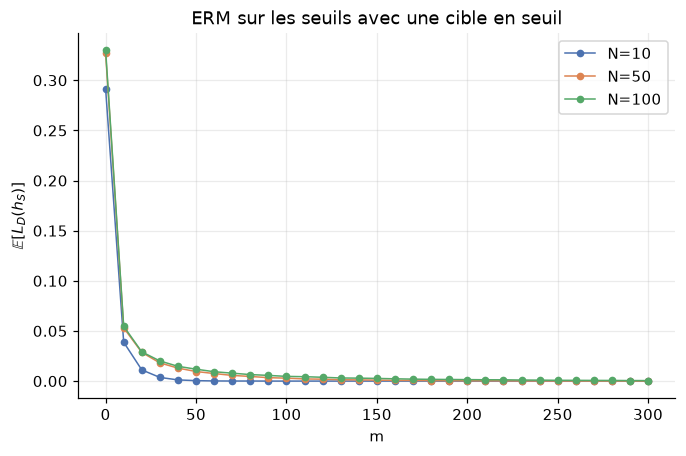

In [27]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for N in N_LIST:
    ax.plot(M_NFL, risk_thr[N], "o-", color=colors_N[N], ms=4, lw=1, label=f"N={N}")
ax.set_xlabel("m")
ax.set_ylabel(r"$\mathbb{E}[L_D(h_S)]$")
ax.set_title("ERM sur les seuils avec une cible en seuil")
ax.legend()
plt.show()

**INTERPRETATION**

Quand la cible est un seuil et que l'apprenant cherche parmi les seuils, le risque tombe très vite : pour $N=50$, il passe de 0.33 sans exemple à 0.05 avec 10 exemples et 0.01 avec 50 exemples. Avec la mémorisation de la partie II, les mêmes tailles d'échantillon donnaient 0.41 et 0.18.

Le risque dépend aussi très peu de la taille du domaine : à $m=50$, il vaut 0.010 pour $N=50$ et 0.012 pour $N=100$, alors qu'avec la mémorisation il passait de 0.18 à 0.30. Dans le tableau, le risque reste sous la valeur de la colonne « Risque maximal dans 95 % des cas », qui est toujours inférieure à la borne du cours (environ 3 fois plus grande pour $N=50$ et $m=50$).

On peut conclure que, si l'hypothèse faite sur la cible est vraie, quelques dizaines d'exemples suffisent pour bien prédire les entrées non vues.

## Tâche 10 : Cibles aléatoires contre cibles en seuil

On compare l'évolution du vrai risque avec $m$ dans trois situations : l'apprenant par mémorisation avec des cibles complètement aléatoires (partie II), l'ERM sur les seuils avec des cibles en seuils(tâche 9), et pour voir le rôle de l'hypothèse sur la cible, l'ERM sur les seuils avec des cibles complètement aléatoires. On reprend les mêmes $N$ et $m$ que précédemment.

In [28]:
risk_thr_on_random = {N: np.array([simulate_erm_thresholds(N, m, N_REP_THR, rng, target="random").mean() for m in M_NFL])
                      for N in N_LIST}

In [29]:
rows = []
for N in N_LIST:
    for m in [10, 50, 100, 200]:
        i = list(M_NFL).index(m)
        rows.append([N, m, fmt(risk_emp[N][i]), fmt(risk_thr_on_random[N][i]), fmt(risk_thr[N][i])])
show_table("Tâche 10 : vrai risque moyen selon la situation",
           ["Taille du domaine N", "Taille d'échantillon m", "Mémorisation, cibles aléatoires",
            "ERM sur les seuils, cibles aléatoires", "ERM sur les seuils, cibles en seuil"], rows)

**Tâche 10 : vrai risque moyen selon la situation**

| Taille du domaine N | Taille d'échantillon m | Mémorisation, cibles aléatoires | ERM sur les seuils, cibles aléatoires | ERM sur les seuils, cibles en seuil |
|---|---|---|---|---|
| 10 | 10 | 0.1750 | 0.3648 | 0.0388 |
| 10 | 50 | 0.0025 | 0.3244 | 4.4e-04 |
| 10 | 100 | 0 | 0.3225 | 0 |
| 10 | 200 | 0 | 0.3198 | 0 |
| 50 | 10 | 0.4087 | 0.4623 | 0.0531 |
| 50 | 50 | 0.1822 | 0.4273 | 0.0095 |
| 50 | 100 | 0.0668 | 0.4164 | 0.0029 |
| 50 | 200 | 0.0086 | 0.4082 | 3.2e-04 |
| 100 | 10 | 0.4525 | 0.4800 | 0.0547 |
| 100 | 50 | 0.3030 | 0.4588 | 0.0119 |
| 100 | 100 | 0.1830 | 0.4455 | 0.0047 |
| 100 | 200 | 0.0671 | 0.4391 | 0.0015 |

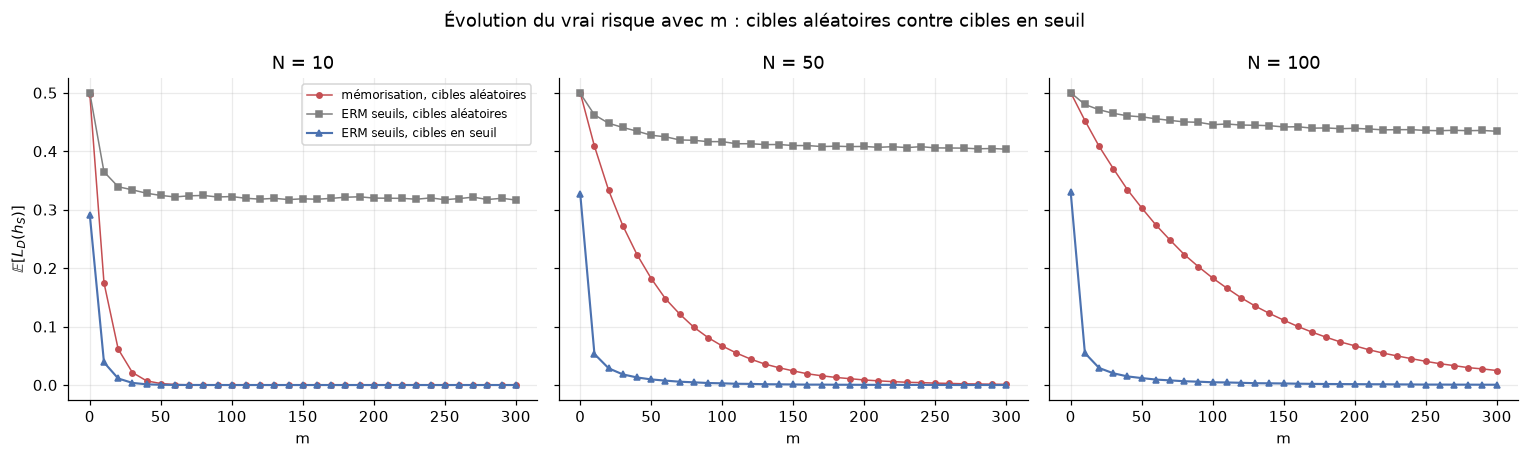

In [30]:
fig, axes = plt.subplots(1, len(N_LIST), figsize=(14, 4.2), sharey=True)
for ax, N in zip(axes, N_LIST):
    ax.plot(M_NFL, risk_emp[N], "o-", color="#C44E52", ms=3.5, lw=1, label="mémorisation, cibles aléatoires")
    ax.plot(M_NFL, risk_thr_on_random[N], "s-", color="gray", ms=3.5, lw=1, label="ERM seuils, cibles aléatoires")
    ax.plot(M_NFL, risk_thr[N], "^-", color="#4C72B0", ms=3.5, lw=1.4, label="ERM seuils, cibles en seuil")
    ax.set_title(f"N = {N}")
    ax.set_xlabel("m")
axes[0].set_ylabel(r"$\mathbb{E}[L_D(h_S)]$")
axes[0].legend(fontsize=8)
fig.suptitle("Évolution du vrai risque avec m : cibles aléatoires contre cibles en seuil")
fig.tight_layout()
plt.show()

**INTERPRETATION**

La courbe bleue (ERM sur les seuils, cible en seuil) tombe presque à zéro dès quelques dizaines d'exemples, quelle que soit la taille du domaine. La courbe rouge (mémorisation, cible aléatoire) descend beaucoup plus lentement, et d'autant plus que $N$ est grand : pour $N=100$, elle vaut encore 0.07 à $m=200$. La différence vient du fait que, pour un seuil, les exemples vus renseignent sur ceux qu'on n'a pas vus : si on a vu un 0 en $x=30$ et un 1 en $x=45$, seules les entrées entre 30 et 45 restent incertaines. Avec une cible aléatoire, le label de $x=30$ ne dit rien sur celui de $x=31$.

La courbe grise montre que l'hypothèse faite sur la cible doit être juste. Avec l'ERM sur les seuils mais une cible aléatoire, le risque ne tombe pas vers zéro : il reste autour de 0.32 pour $N=10$, 0.41 pour $N=50$ et 0.44 pour $N=100$, car aucun seuil ne représente bien une cible aléatoire. Ce n'est donc pas l'ERM seul qui permet de généraliser, c'est le fait que la classe d'hypothèses corresponde à la forme de la cible.

On peut conclure que la mémorisation peut représenter n'importe quelle cible mais demande de voir presque tout le domaine, alors que les seuils généralisent très vite quand la cible est un seuil.

## Tâche 11 : Analyse finale

### Convergence uniforme
Le risque mesuré $L_S(h)$ est la moyenne de $m$ erreurs : il est juste en moyenne et se resserre autour de $L_D(h)$ quand $m$ augmente avec une probabilité d'écart qui décroît (de manière exponentiel) selon Hoeffding. 

L'ERM choisit l'hypothèse qui a l'air la meilleure sur l'échantillon, donc il faut que toutes les hypothèses soient bien mesurées en même temps : sinon il pourrait justement choisir une hypothèse dont l'erreur est mal estimée. 

Plus la classe est grande, plus il y a de chances qu'une hypothèse soit mal mesurée, donc il faut plus de données, mais seulement de l'ordre de $\log|\mathcal H|$ : environ 115 exemples de plus à chaque fois que $|\mathcal H|$ est multiplié par 10, pour $\epsilon=0.1$. 

Les bornes sont conservatrices parce qu'elles sont écrites pour le pire cas : Hoeffding ignore que certaines hypothèses sont plus régulières, et la borne de l'union ignore que des hypothèses proches se trompent sur les mêmes échantillons. Ce sont des garanties suffisantes : le $m$ expérimental est 1.6 à 2.6 fois plus petit que le $m$ théorique.

### No-Free-Lunch
Si la cible est complètement aléatoire, le label d'une entrée non vue est un pile ou face : quelle que soit la règle, on se trompe une fois sur deux sur ces entrées. En effet, le risque devient petit uniquement si tout le domaine a été vu. 

L'expérience montre qu'on ne peut pas deviner des labels arbitraires à partir de l'échantillon seul : prédire 0, 1 ou au hasard donne le même risque, et une règle n'est meilleure que si les cibles ont une structure.

### Biais inductif 
Supposer que la cible est un seuil et chercher parmi les seuils est une connaissance a priori : les labels de deux entrées proches sont liés, donc les exemples vus renseignent sur les entrées non vues. 

Avec 50 exemples sur un domaine de 50 entrées, le risque est d'environ 1 %, contre 18 % pour la mémorisation. Cette hypothèse doit être juste : avec une cible aléatoire, l'ERM sur les seuils reste à un risque d'environ 0.41.